In [ ]:
!pip install pandas numpy matplotlib seaborn wordcloud openpyxl

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
dataset_path = "Exercise4_Flipkart_Dummy_Dataset.csv"

print("Current working directory:")
print(os.getcwd())

if os.path.exists(dataset_path):
    print("\nDataset file found successfully!")
else:
    print("\nDataset not found!")
    print("Please copy the CSV file into the current working directory.")

Current working directory:
C:\Users\rajkh

Dataset file found successfully!


In [3]:
df = pd.read_csv(
    dataset_path,
    encoding="utf-8-sig"
)

print("Dataset loaded successfully!")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head(10))

Dataset loaded successfully!
Number of rows: 1000
Number of columns: 4


,product_name,product_price,rate,summary
0,Lenovo Laptop,"₹50,294",3.0,Decent product for the price
1,Realme Narzo 60,"₹18,865",5.0,Really happy with this purchase
2,Prestige Electric Kettle,"₹1,177",2.0,"Not as described, would not recommend"
3,Redmi Note 13 5G,"₹17,345",3.0,"Useful product, however packaging needs improv..."
4,Prestige Electric Kettle,"₹1,278",3.0,"Useful product, however packaging needs improv..."
5,Mi Power Bank 20000mAh,"₹2,361",5.0,Product quality is excellent and packaging was...
6,Safari Trolley Bag,"₹2,952",5.0,Really happy with this purchase
7,Noise ColorFit Smartwatch,"₹2,300",3.0,Decent product for the price
8,Sony Headphones,"₹4,081",2.0,Disappointed with the product quality
9,Safari Trolley Bag,"₹3,020",2.0,"Not as described, would not recommend"


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

Column names:
['product_name', 'product_price', 'rate', 'summary']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_name   1000 non-null   str    
 1   product_price  1000 non-null   str    
 2   rate           1000 non-null   float64
 3   summary        1000 non-null   str    
dtypes: float64(1), str(3)
memory usage: 95.4 KB

Missing values:


product_name     0
product_price    0
rate             0
summary          0
dtype: int64


Statistical summary:


,product_name,product_price,rate,summary
count,1000,1000,1000.000000,1000
unique,15,912,NaN,17
top,Sony Headphones,"₹2,713",NaN,Value for money and works perfectly
freq,83,4,NaN,124
mean,NaN,NaN,4.049000,NaN
std,NaN,NaN,1.078778,NaN
min,NaN,NaN,1.000000,NaN
25%,NaN,NaN,4.000000,NaN
50%,NaN,NaN,4.000000,NaN
75%,NaN,NaN,5.000000,NaN


In [5]:
df_clean = df.copy()

# 1. Clean product names
df_clean["product_name"] = (
    df_clean["product_name"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# 2. Clean product prices
df_clean["product_price"] = (
    df_clean["product_price"]
    .astype(str)
    .str.replace(r"[₹$,\s]", "", regex=True)
)

df_clean["product_price"] = pd.to_numeric(
    df_clean["product_price"],
    errors="coerce"
)

# 3. Clean ratings
df_clean["rate"] = (
    df_clean["rate"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)

df_clean["rate"] = pd.to_numeric(
    df_clean["rate"],
    errors="coerce"
)

# 4. Clean review summaries
df_clean["summary"] = (
    df_clean["summary"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# 5. Remove invalid records
df_clean = df_clean.dropna(
    subset=["product_price", "rate"]
)

df_clean = df_clean[
    (df_clean["product_name"] != "") &
    (df_clean["product_price"] > 0) &
    (df_clean["rate"] >= 1) &
    (df_clean["rate"] <= 5)
]

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

display(df_clean.head(10))

Original records: 1000
Cleaned records: 1000


,product_name,product_price,rate,summary
0,Lenovo Laptop,50294,3.0,Decent product for the price
1,Realme Narzo 60,18865,5.0,Really happy with this purchase
2,Prestige Electric Kettle,1177,2.0,"Not as described, would not recommend"
3,Redmi Note 13 5G,17345,3.0,"Useful product, however packaging needs improv..."
4,Prestige Electric Kettle,1278,3.0,"Useful product, however packaging needs improv..."
5,Mi Power Bank 20000mAh,2361,5.0,Product quality is excellent and packaging was...
6,Safari Trolley Bag,2952,5.0,Really happy with this purchase
7,Noise ColorFit Smartwatch,2300,3.0,Decent product for the price
8,Sony Headphones,4081,2.0,Disappointed with the product quality
9,Safari Trolley Bag,3020,2.0,"Not as described, would not recommend"


In [6]:
items = (
    df_clean.groupby("product_name")
    .agg(
        Mean_Rating=("rate", "mean"),
        Mean_Price=("product_price", "mean"),
        Total_Reviews=("rate", "count")
    )
    .reset_index()
)

items["Mean_Rating"] = items["Mean_Rating"].round(2)
items["Mean_Price"] = items["Mean_Price"].round(2)

items = items.sort_values(
    by="Mean_Rating",
    ascending=False
)

print("Product-wise summary:")
display(items)

print("Total unique products:", len(items))

Product-wise summary:


,product_name,Mean_Rating,Mean_Price,Total_Reviews
12,Samsung Galaxy M14 5G,4.35,13878.12,43
9,Realme Narzo 60,4.28,18106.59,69
11,Safari Trolley Bag,4.22,3002.69,74
2,Lenovo Laptop,4.16,52706.00,74
5,Philips Mixer Grinder,4.15,3495.35,75
3,Mi Power Bank 20000mAh,4.13,2188.25,71
14,boAt Rockerz 450,4.07,1498.53,68
10,Redmi Note 13 5G,4.06,16840.62,71
8,Puma Running Shoes,4.03,2516.77,73
13,Sony Headphones,4.01,4009.19,83


Total unique products: 15


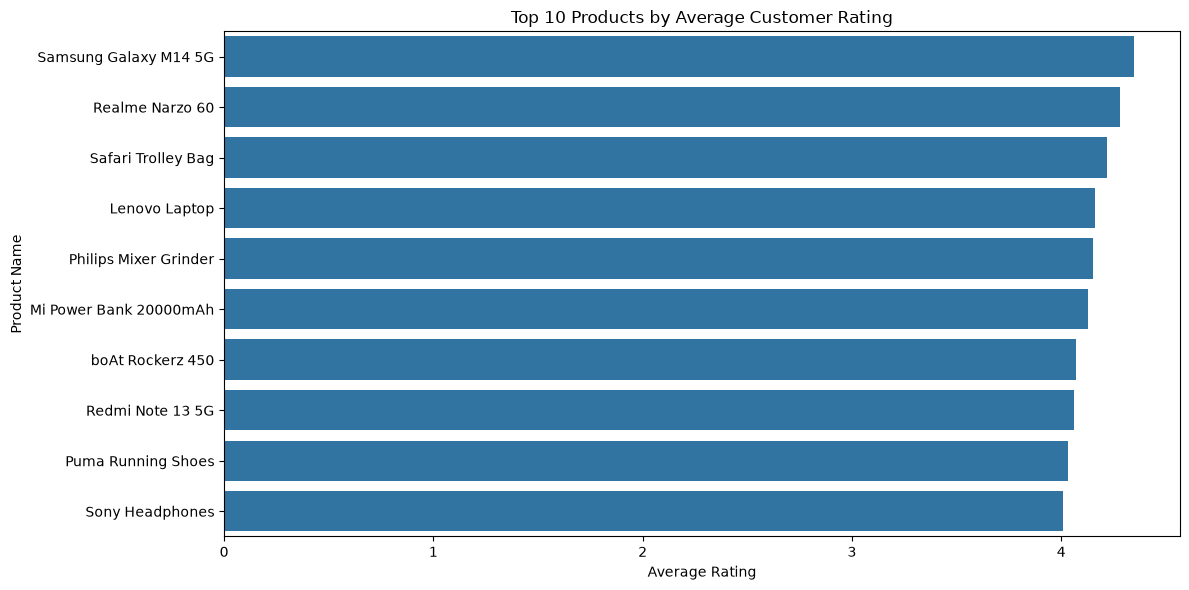

In [7]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=items.sort_values(
        "Mean_Rating", ascending=False
    ).head(10),
    x="Mean_Rating",
    y="product_name"
)

plt.title("Top 10 Products by Average Customer Rating")
plt.xlabel("Average Rating")
plt.ylabel("Product Name")

plt.tight_layout()

plt.savefig(
    "Exercise4_Product_Ratings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

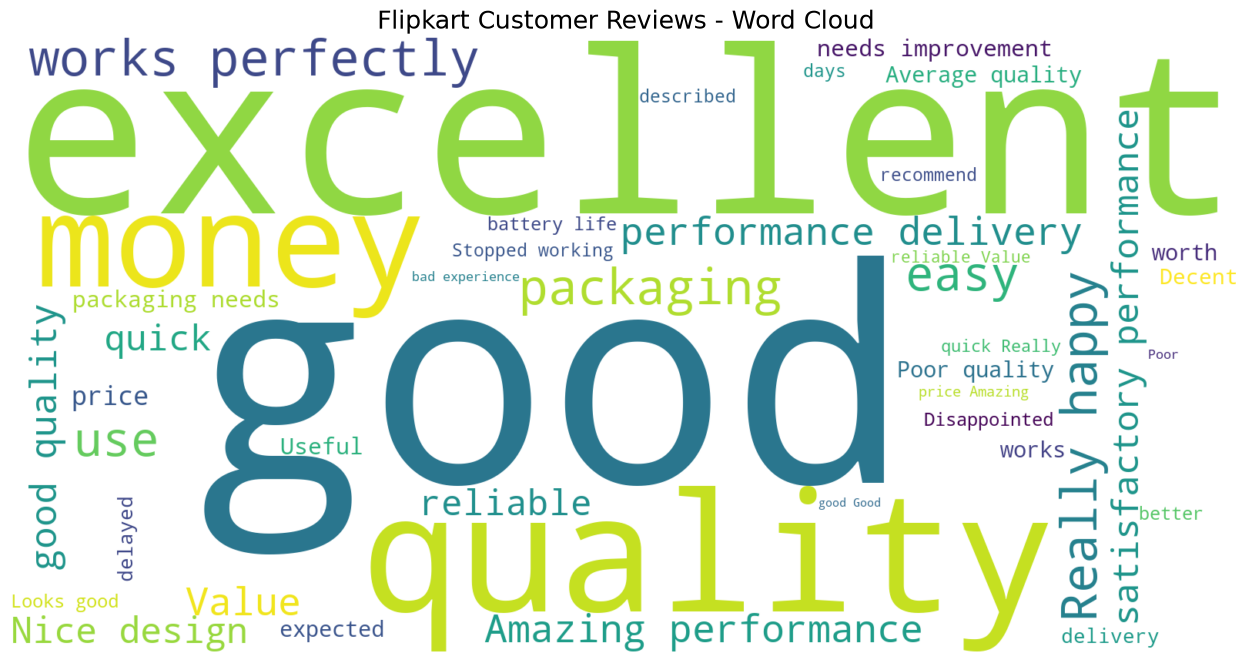

In [8]:
text_data = " ".join(
    df_clean["summary"].dropna().astype(str)
)

if not text_data.strip():
    raise ValueError("No review summary text is available.")

stopwords = set(STOPWORDS)

stopwords.update([
    "product",
    "flipkart",
    "amazon",
    "item",
    "purchase",
    "buy",
    "one",
    "also",
    "got"
])

wordcloud = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    stopwords=stopwords,
    max_words=150,
    colormap="viridis"
).generate(text_data)

plt.figure(figsize=(16, 8))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Flipkart Customer Reviews - Word Cloud",
    fontsize=18
)

plt.savefig(
    "Exercise4_Flipkart_WordCloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
words = re.findall(
    r"\b[a-zA-Z]{3,}\b",
    text_data.lower()
)

filtered_words = [
    word for word in words
    if word not in stopwords
]

word_frequency = Counter(filtered_words)

frequent_words = pd.DataFrame(
    word_frequency.most_common(15),
    columns=["Word", "Frequency"]
)

print("Top 15 frequently used words:")
display(frequent_words)

Top 15 frequently used words:


,Word,Frequency
0,good,370
1,quality,296
2,excellent,218
3,performance,211
4,works,153
5,packaging,150
6,delivery,131
7,value,124
8,money,124
9,perfectly,124


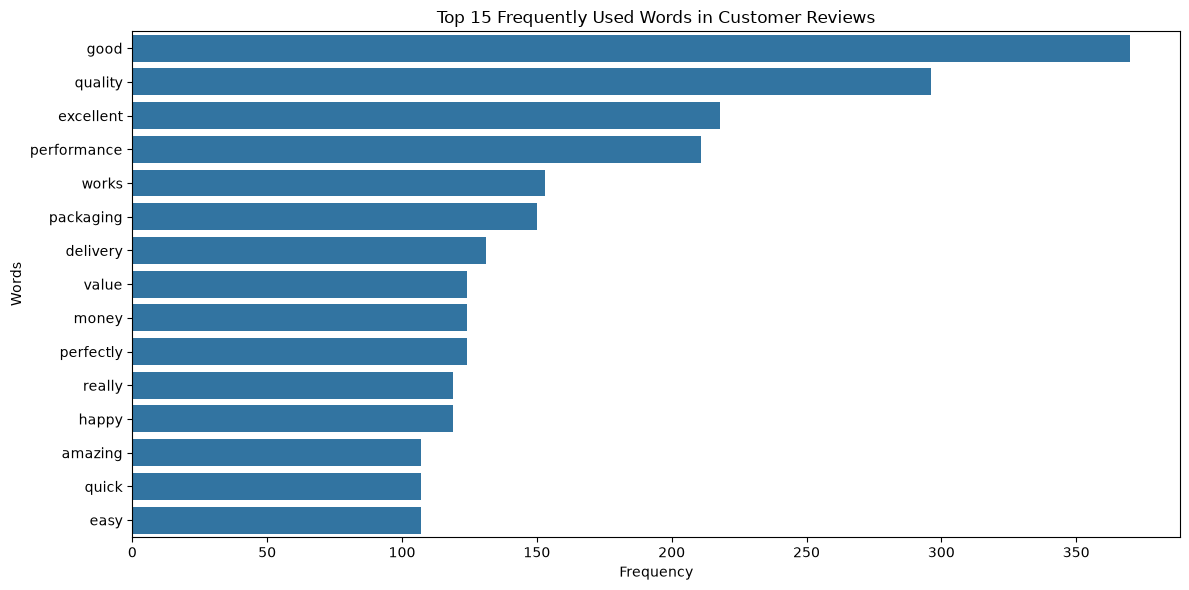

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=frequent_words,
    x="Frequency",
    y="Word"
)

plt.title("Top 15 Frequently Used Words in Customer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.tight_layout()

plt.savefig(
    "Exercise4_Top_Words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
output_file = "Exercise4_Flipkart_Analytics.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    items.to_excel(
        writer,
        sheet_name="Product_Summary",
        index=False
    )

    frequent_words.to_excel(
        writer,
        sheet_name="Word_Frequency",
        index=False
    )

    df_clean.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

print("Excel report generated successfully!")
print("File name:", output_file)

Excel report generated successfully!
File name: Exercise4_Flipkart_Analytics.xlsx


In [12]:
output_files = [
    "Exercise4_Flipkart_Dummy_Dataset.csv",
    "Exercise4_Flipkart_Analytics.xlsx",
    "Exercise4_Flipkart_WordCloud.png",
    "Exercise4_Product_Ratings.png",
    "Exercise4_Top_Words.png"
]

print("EXERCISE 4 - OUTPUT VERIFICATION")
print("-" * 45)

for file in output_files:
    if os.path.exists(file):
        print("SUCCESS:", file)
    else:
        print("NOT FOUND:", file)

EXERCISE 4 - OUTPUT VERIFICATION
---------------------------------------------
SUCCESS: Exercise4_Flipkart_Dummy_Dataset.csv
SUCCESS: Exercise4_Flipkart_Analytics.xlsx
SUCCESS: Exercise4_Flipkart_WordCloud.png
SUCCESS: Exercise4_Product_Ratings.png
SUCCESS: Exercise4_Top_Words.png
